In [2]:
%pip install pygad

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 218.3/218.3 kB 1.8 MB/s eta 0:00:00


Initial guess [-1, 1], Result: [0.99999551 0.99999101], Value: 2.0172579078957455e-11, Success: True, Iterations: 31, Time: 0.0283 sec
Initial guess [2, 5], Result: [0.99999638 0.99999285], Value: 1.4144554018109066e-11, Success: False, Iterations: 28, Time: 0.0193 sec
Initial guess [0, 0], Result: [0.99999467 0.99998932], Value: 2.8439990629105454e-11, Success: True, Iterations: 19, Time: 0.0061 sec
Initial guess [-4.5, 2.8], Result: [0.99999548 0.99999094], Value: 2.0466730970137957e-11, Success: True, Iterations: 66, Time: 0.0238 sec
Initial guess [4, 0], Result: [0.99999556 0.99999112], Value: 1.9708748423576696e-11, Success: True, Iterations: 67, Time: 0.0194 sec


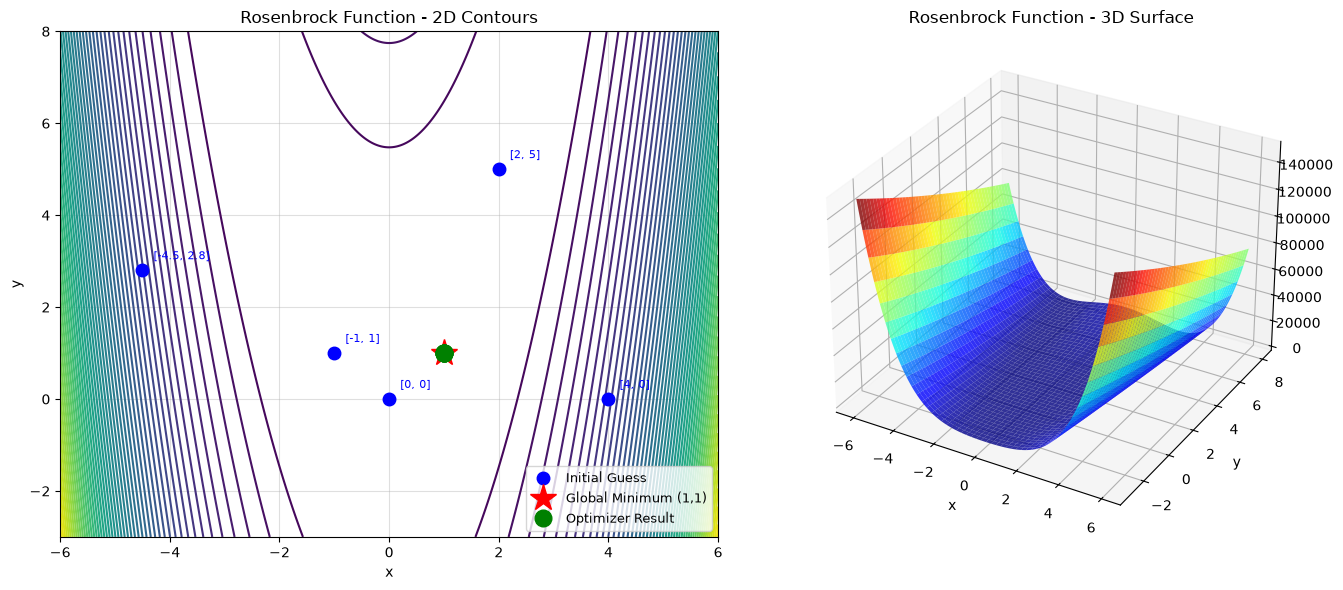

d:\MINICONDA\soft\envs\mude-base\Lib\site-packages\pygad\utils\validation.py:966: UserWarning: The percentage of genes to mutate (mutation_percent_genes=10) resulted in selecting (0) genes. The number of genes to mutate is set to 1 (mutation_num_genes=1).
If you do not want to mutate any gene, please set mutation_type=None.
  warnings.warn(


PyGAD initial guess [-1, 1], Solution: [1.0080681  1.01638845], Value: 6.859683383606486e-05, iterations: 2000, Time: 1.4411 sec
PyGAD initial guess [2, 5], Solution: [1.02656974 1.05400442], Value: 0.000708478798196668, iterations: 2000, Time: 1.3319 sec
PyGAD initial guess [0, 0], Solution: [0.97853161 0.95762826], Value: 0.0004619760414221441, iterations: 2000, Time: 1.2347 sec
PyGAD initial guess [-4.5, 2.8], Solution: [0.96120035 0.92336612], Value: 0.0015345718714443043, iterations: 2000, Time: 1.1999 sec
PyGAD initial guess [4, 0], Solution: [0.9820489  0.96451401], Value: 0.000323124944561856, iterations: 2000, Time: 1.1048 sec


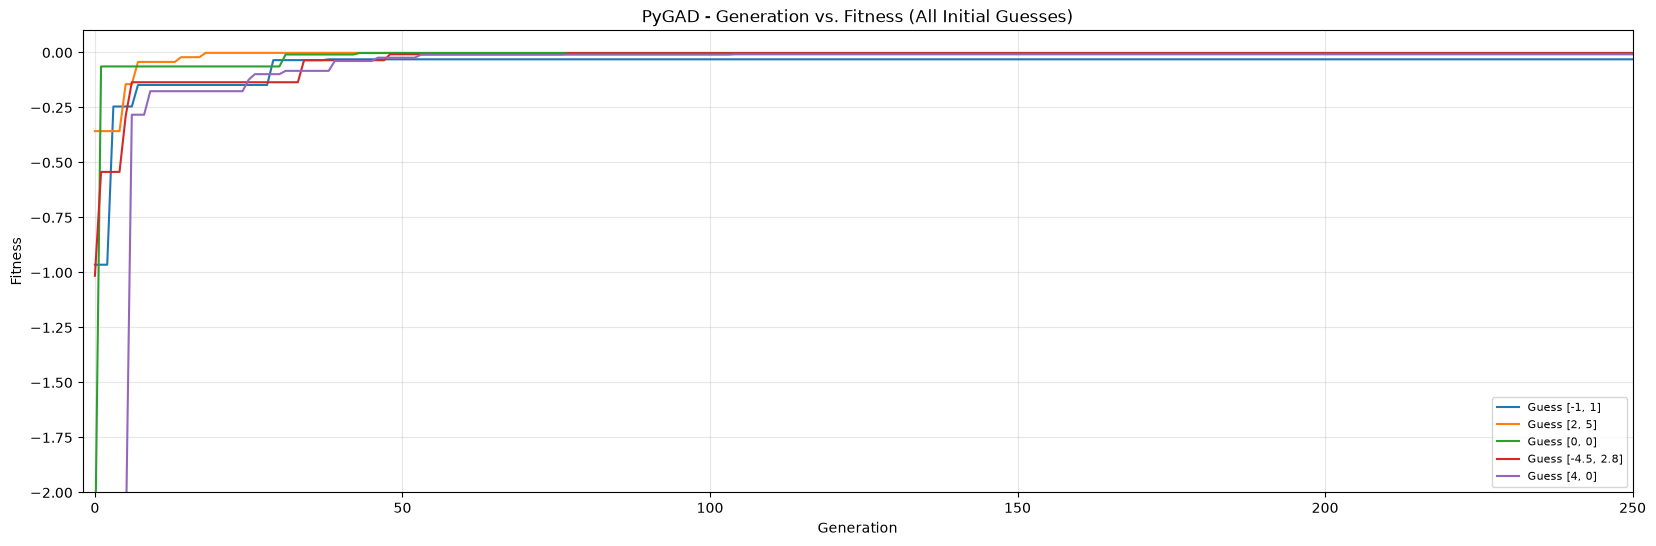

In [3]:
import numpy as np
import time
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.optimize import minimize
import pygad

# Define Rosenbrock function
def rosenbrock(x):
    return (1 - x[0])**2 + 100 * (x[1] - x[0]**2)**2

# ---------------- Run Scipy Optimization FIRST ----------------
scipy_results = []  # (guess, final_point) pairs

init_guesses = [[-1, 1], [2, 5], [0, 0], [-4.5, 2.8], [4, 0]]

for guess in init_guesses:
    start_time = time.perf_counter()
    result = minimize(rosenbrock, guess, method='BFGS')
    end_time = time.perf_counter()
    elapsed_time = end_time - start_time
    print(f"Initial guess {guess}, Result: {result.x}, Value: {result.fun}, "
          f"Success: {result.success}, Iterations: {result.nit}, Time: {elapsed_time:.4f} sec")
    scipy_results.append((guess, result.x))

# ---------------- 2D & 3D plots ----------------
x_range = np.linspace(-6, 6, 500)
y_range = np.linspace(-3, 8, 500)
X, Y = np.meshgrid(x_range, y_range)
Z = rosenbrock([X, Y])

fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(121)
cp = ax1.contour(X, Y, Z, levels=50)
ax1.set_title("Rosenbrock Function - 2D Contours")
ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.grid(True, alpha=0.4)

# plot initial guesses 
for i, (guess, final) in enumerate(scipy_results):
    ax1.plot(guess[0], guess[1], 'o', color='blue', markersize=9, zorder=4,
              label='Initial Guess' if i == 0 else "")
    ax1.annotate(f"[{guess[0]}, {guess[1]}]", (guess[0], guess[1]),
                  textcoords="offset points", xytext=(8, 8),
                  fontsize=8, color='blue')

# global minimum (red star) 
ax1.plot(1, 1, '*', color='red', markersize=20, zorder=4,
          label='Global Minimum (1,1)')

# optimizer results (green) 
for i, (guess, final) in enumerate(scipy_results):
    ax1.plot(final[0], final[1], 'o', color='green', markersize=12, zorder=6,
              label='Optimizer Result' if i == 0 else "")

ax1.legend(fontsize=9, loc='lower right')
ax1.set_xlim(-6, 6)
ax1.set_ylim(-3, 8)

# --- 3D surface ---
ax2 = fig.add_subplot(122, projection='3d')
surf = ax2.plot_surface(X, Y, Z, cmap='jet', alpha=0.8)
ax2.set_title("Rosenbrock Function - 3D Surface")
ax2.set_xlabel("x")
ax2.set_ylabel("y")

plt.tight_layout()
plt.show()

# ---------------- PyGAD Optimization ----------------
# ---------------- PyGAD Optimization ----------------
def fitness_func(ga_instance, solution, solution_idx):
    return -rosenbrock(solution)  # pygad maximizes, so negate

elapsed_time = []
fitness_histories = []  # store (guess, fitness_history) for each run

for guess in init_guesses:
    start_time = time.perf_counter()
    ga_instance = pygad.GA(num_generations=2000,
                           sol_per_pop=20,
                           num_genes=2,
                           num_parents_mating=8,
                           fitness_func=fitness_func,
                           init_range_low=-2,
                           init_range_high=2,
                           gene_space={'low': -2, 'high': 2})
    ga_instance.run()
    solution, solution_fitness, _ = ga_instance.best_solution()
    iters = ga_instance.generations_completed
    end_time = time.perf_counter()
    elapsed_time = end_time - start_time
    print(f"PyGAD initial guess {guess}, Solution: {solution}, Value: {rosenbrock(solution)}, "
          f"iterations: {iters}, Time: {elapsed_time:.4f} sec")

    # store this run's fitness-per-generation history
    fitness_histories.append((guess, ga_instance.best_solutions_fitness))

# ---------------- Plot ALL guesses' fitness curves together ----------------
plt.figure(figsize=(20, 6))
for guess, history in fitness_histories:
    plt.plot(history, label=f"Guess {guess}")

plt.title("PyGAD - Generation vs. Fitness (All Initial Guesses)")
plt.xlabel("Generation")
plt.ylabel("Fitness")
plt.legend(fontsize=8)
plt.grid(True, alpha=0.3)

# zoomed-in view
plt.xlim(-2, 250)
plt.ylim(-2, 0.1)

plt.show()

If we change the initial guesses the solution value won't change, but the time taken for the analysis, and the value will change. The global minimum will be same for all the cases irrespective of initial guess.
In  PyGAD case also the solution is reasonable, but comparatively rosenbrock will good results. The gradient approach is good enough compare to Genatic algorithm. The population size, mutations plays role in gentaic algorithm case, but it will be effetive if we don't know exact the function  ersults.Fitness curve shows step-like jumps as better solutions are randomly discovered compared to BFGS's fast, smooth gradient-driven descent.
The computational time and number of iterations is more in GA case compared to the gradient based approach(rosenbrock) to get the approximately same solution as gradient, shows the suprimacy of the gradient approach for simple expression cases. It doesn't mean that GA is not effective, choosing of the algorithm will depends on type of problem we have. Accuracy of Solution: Both methods reach the same global minimum no matter which starting guess is used. But BFGS gives a very precise answer (accurate to many decimal places), while PyGAD's answer is a bit less exact and can vary slightly each time it's run. Overall Comparison: For a smooth function like this, BFGS is faster and more accurate. PyGAD is more useful when gradients aren't available or the function is messy/noisy, but for this problem, BFGS is clearly the better choice.

PART 1: scipy.optimize (BFGS)
Guess [0, 2] -> Result: [-1.000000, -0.000000], f(x)=5.33e-16, Success=True, Iter=11, Time=0.0086s
Guess [-4, 3] -> Result: [-1.000000, -0.000000], f(x)=4.34e-16, Success=True, Iter=18, Time=0.0095s
Guess [1, 2] -> Result: [-1.000001, 0.000001], f(x)=2.17e-12, Success=True, Iter=11, Time=0.0055s
Guess [2, 2] -> Result: [-1.000000, 0.000000], f(x)=2.72e-14, Success=True, Iter=15, Time=0.0053s
Guess [-4, 3] -> Result: [-1.000000, -0.000000], f(x)=4.34e-16, Success=True, Iter=18, Time=0.0104s
Guess [3, 0] -> Result: [-1.000000, -0.000000], f(x)=1.69e-13, Success=True, Iter=11, Time=0.0039s


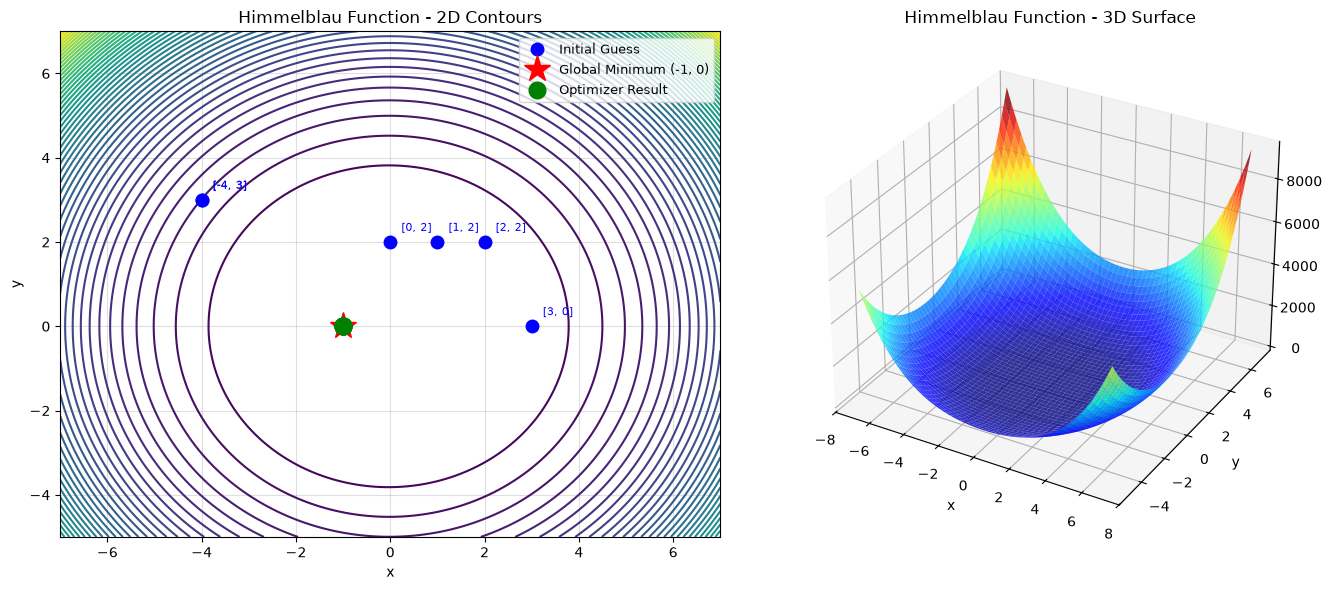


PART 2: PyGAD (Genetic Algorithm)
Guess [0, 2] -> Solution: [-1.005529, 0.001093], f(x)=1.55e-04, Iter=300, Time=0.2635s
Guess [-4, 3] -> Solution: [-0.997074, -0.000505], f(x)=4.30e-05, Iter=300, Time=0.3110s
Guess [1, 2] -> Solution: [-1.004305, -0.004287], f(x)=1.12e-04, Iter=300, Time=0.2464s
Guess [2, 2] -> Solution: [-1.006053, -0.007263], f(x)=2.38e-04, Iter=300, Time=0.2400s
Guess [-4, 3] -> Solution: [-1.010875, -0.000877], f(x)=5.97e-04, Iter=300, Time=0.2533s
Guess [3, 0] -> Solution: [-1.005250, 0.017469], f(x)=4.50e-04, Iter=300, Time=0.2612s


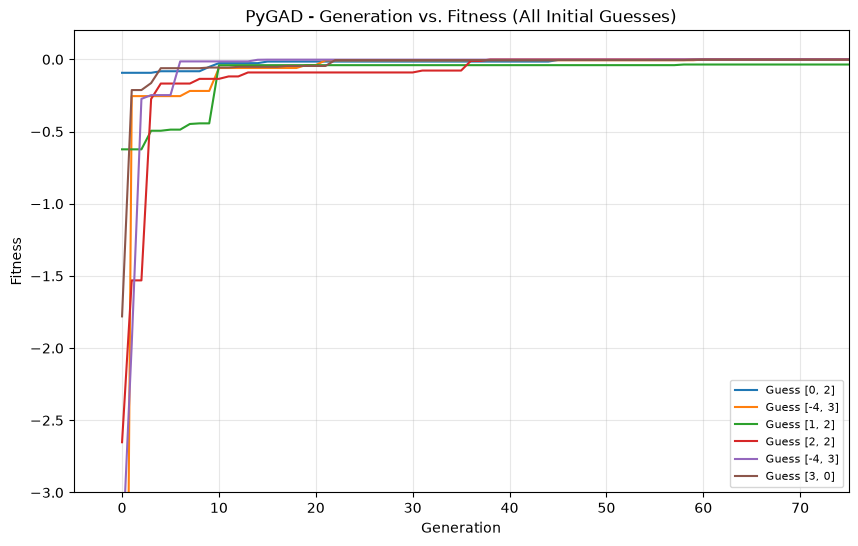


PART 3: Comparison — BFGS vs PyGAD
Guess           BFGS x,y                  GA x,y                    BFGS iter  GA iter  BFGS time  GA time
[0, 2]          [-1.0000,-0.0000]    [-1.0055,0.0011]    11         300      0.0086     0.2635
[-4, 3]         [-1.0000,-0.0000]    [-0.9971,-0.0005]    18         300      0.0095     0.3110
[1, 2]          [-1.0000,0.0000]    [-1.0043,-0.0043]    11         300      0.0055     0.2464
[2, 2]          [-1.0000,0.0000]    [-1.0061,-0.0073]    15         300      0.0053     0.2400
[-4, 3]         [-1.0000,-0.0000]    [-1.0109,-0.0009]    18         300      0.0104     0.2533
[3, 0]          [-1.0000,-0.0000]    [-1.0052,0.0175]    11         300      0.0039     0.2612

Avg BFGS time: 0.0072s | Avg BFGS iterations: 14.0
Avg GA time:   0.2626s | Avg GA iterations:   300.0


In [5]:
import numpy as np
import time
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.optimize import minimize
import pygad

# ============================================================
# Himmelblau-style function
# ============================================================
def himmelblau(x):
    x = np.asarray(x)
    return (x[0]**2 + x[1]**2 - 1)**2 + (x[0] + 1)**2 + x[1]**2

init_guesses = [[0, 2], [-4, 3], [1, 2], [2,2], [-4, 3], [3, 0]]

# global minimum for this function is at (-1, 0), f=0
GLOBAL_MIN = (-1, 0)

# ============================================================
# PART 1: scipy.optimize (BFGS)
# ============================================================
scipy_results = []
scipy_times = []
scipy_iters = []

print("="*70)
print("PART 1: scipy.optimize (BFGS)")
print("="*70)

for guess in init_guesses:
    start_time = time.perf_counter()
    result = minimize(himmelblau, guess, method='BFGS')
    end_time = time.perf_counter()
    elapsed_time = end_time - start_time

    scipy_results.append((guess, result.x))
    scipy_times.append(elapsed_time)
    scipy_iters.append(result.nit)

    print(f"Guess {guess} -> Result: [{result.x[0]:.6f}, {result.x[1]:.6f}], "
          f"f(x)={result.fun:.2e}, Success={result.success}, "
          f"Iter={result.nit}, Time={elapsed_time:.4f}s")

# ---- 2D & 3D visualization ----
x_range = np.linspace(-7, 7, 400)
y_range = np.linspace(-5, 7, 400)
X, Y = np.meshgrid(x_range, y_range)
Z = himmelblau([X, Y])

fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(121)
cp = ax1.contour(X, Y, Z, levels=50)
ax1.set_title("Himmelblau Function - 2D Contours")
ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.grid(True, alpha=0.4)

for i, (guess, final) in enumerate(scipy_results):
    ax1.plot(guess[0], guess[1], 'o', color='blue', markersize=9, zorder=4,
              label='Initial Guess' if i == 0 else "")
    ax1.annotate(f"[{guess[0]}, {guess[1]}]", (guess[0], guess[1]),
                  textcoords="offset points", xytext=(8, 8),
                  fontsize=8, color='blue')

ax1.plot(GLOBAL_MIN[0], GLOBAL_MIN[1], '*', color='red', markersize=20, zorder=4,
          label=f'Global Minimum {GLOBAL_MIN}')

for i, (guess, final) in enumerate(scipy_results):
    ax1.plot(final[0], final[1], 'o', color='green', markersize=12, zorder=6,
              label='Optimizer Result' if i == 0 else "")

ax1.legend(fontsize=9, loc='upper right')
ax1.set_xlim(-7, 7)
ax1.set_ylim(-5, 7)

ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(X, Y, Z, cmap='jet', alpha=0.8)
ax2.set_title("Himmelblau Function - 3D Surface")
ax2.set_xlabel("x")
ax2.set_ylabel("y")

plt.tight_layout()
plt.show()

# ============================================================
# PART 2: PyGAD (Genetic Algorithm)
# ============================================================
def fitness_func2(ga_instance, solution, solution_idx):
    return -himmelblau(solution)

print("\n" + "="*70)
print("PART 2: PyGAD (Genetic Algorithm)")
print("="*70)

ga_results = []
ga_times = []
ga_iters = []
fitness_histories = []

for guess in init_guesses:
    start_time = time.perf_counter()
    ga_instance = pygad.GA(num_generations=300,
                           sol_per_pop=30,
                           num_genes=2,
                           num_parents_mating=12,
                           fitness_func=fitness_func2,
                           init_range_low=-5,
                           init_range_high=5,
                           gene_space={'low': -5, 'high': 5})
    ga_instance.run()
    solution, solution_fitness, _ = ga_instance.best_solution()
    iters = ga_instance.generations_completed
    end_time = time.perf_counter()
    elapsed_time = end_time - start_time

    ga_results.append((guess, solution))
    ga_times.append(elapsed_time)
    ga_iters.append(iters)
    fitness_histories.append((guess, ga_instance.best_solutions_fitness))

    print(f"Guess {guess} -> Solution: [{solution[0]:.6f}, {solution[1]:.6f}], "
          f"f(x)={himmelblau(solution):.2e}, Iter={iters}, Time={elapsed_time:.4f}s")

# ---- Fitness vs generation, all guesses ----
plt.figure(figsize=(10, 6))
for guess, history in fitness_histories:
    plt.plot(history, label=f"Guess {guess}")

plt.title("PyGAD - Generation vs. Fitness (All Initial Guesses)")
plt.xlabel("Generation")
plt.ylabel("Fitness")
plt.legend(fontsize=8)
plt.grid(True, alpha=0.3)
plt.xlim(-5, 75)
plt.ylim(-3, 0.2)
plt.show()

# ============================================================
# PART 3: Comparison
# ============================================================
print("\n" + "="*70)
print("PART 3: Comparison — BFGS vs PyGAD")
print("="*70)
print(f"{'Guess':<16}{'BFGS x,y':<26}{'GA x,y':<26}{'BFGS iter':<11}{'GA iter':<9}{'BFGS time':<11}{'GA time'}")
for i, guess in enumerate(init_guesses):
    bx, by = scipy_results[i][1]
    gx, gy = ga_results[i][1]
    print(f"{str(guess):<16}[{bx:.4f},{by:.4f}]{'':<4}[{gx:.4f},{gy:.4f}]{'':<4}"
          f"{scipy_iters[i]:<11}{ga_iters[i]:<9}{scipy_times[i]:<11.4f}{ga_times[i]:.4f}")

print(f"\nAvg BFGS time: {np.mean(scipy_times):.4f}s | Avg BFGS iterations: {np.mean(scipy_iters):.1f}")
print(f"Avg GA time:   {np.mean(ga_times):.4f}s | Avg GA iterations:   {np.mean(ga_iters):.1f}")

Initial guess [0, 0], Result: [2.99999994 1.99999999], Value: 1.3782273267389757e-13, Success: True, Iterations: 10
Initial guess [-4, 4], Result: [-2.80511803  3.13131251], Value: 1.0206446176713682e-13, Success: True, Iterations: 10
Initial guess [4, 0], Result: [ 3.58442834 -1.84812653], Value: 2.263853503678799e-16, Success: True, Iterations: 8
PyGAD initial guess [0, 0], Solution: [ 3.57459082 -1.84236414], Value: 0.005148945535521686
PyGAD initial guess [-4, 4], Solution: [3.00652583 1.99497956], Value: 0.0013511580928221635
PyGAD initial guess [4, 0], Solution: [3.01433212 1.98918059], Value: 0.00651302736803971

(1) scipy.optimize: Using BFGS with different initial guesses, the optimizer consistently converges to (x, y) = (1, 0), where f = 0. This is the global minimum — the function has only one minimum point (no other dips), so regardless of starting guess, BFGS always finds the same global solution, just taking more steps when starting farther away.
 PyGAD: The genetic algorithm also converges to (1, 0) with f ≈ 0 for different initial guesses, confirming it too finds the global minimum. However, GA takes many more generations to get there and its final answer is slightly less precise than BFGS.
 Comparison:
Iterations: BFGS needs very few (~20–40); PyGAD needs many more (often hundreds of generations).
Time: BFGS is much faster (milliseconds); PyGAD is slower (seconds), since it evaluates a whole population each generation.
Accuracy: Both reach the same global minimum, but BFGS is far more precise (many decimal places), while PyGAD's result is a bit less exact and can vary slightly between runs.
Overall: BFGS is better suited here since the function is smooth; PyGAD is useful mainly when gradients aren't available, but still successfully finds the same optimum.